# NYC Taxi Analysis: Demand, Traffic Speed and Driver Earnings

This notebook analyzes three months of NYC yellow taxi trips (January to March 2025) to understand when and where taxi drivers earn the most. The data contains about 11 million trips, so PySpark (Google Colab) is used for processing and matplotlib for the charts.

**Problem Statement:** A taxi fleet operator wants to schedule its drivers more effectively. The analysis looks at when demand is highest, when traffic is slowest, and when a driver's time is worth the most.

## 1. Setup
Connect Google Drive, install PySpark and start a Spark session.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install pyspark

In [3]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("nyc_taxi_analysis") \
    .getOrCreate()

## 2. Load the Data
Read the three monthly files and combine them into one table.

In [4]:
path = "/content/drive/MyDrive/nyc-taxi-driver-scheduling/data/"

jan = spark.read.parquet(path + "yellow_tripdata_2025-01.parquet")
feb = spark.read.parquet(path + "yellow_tripdata_2025-02.parquet")
mar = spark.read.parquet(path + "yellow_tripdata_2025-03.parquet")

df = jan.unionByName(feb).unionByName(mar)

In [5]:
print(df.count())
df.printSchema()

11198026
root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)
 |-- cbd_congestion_fee: double (nullable = true)



## 3. Initial Data Exploration
Inspect a sample of rows, the minimum and maximum values, and the date range.

In [6]:
df.select("tpep_pickup_datetime", "tpep_dropoff_datetime", "trip_distance", "PULocationID", "fare_amount").show(5)

+--------------------+---------------------+-------------+------------+-----------+
|tpep_pickup_datetime|tpep_dropoff_datetime|trip_distance|PULocationID|fare_amount|
+--------------------+---------------------+-------------+------------+-----------+
| 2025-01-01 00:18:38|  2025-01-01 00:26:59|          1.6|         229|       10.0|
| 2025-01-01 00:32:40|  2025-01-01 00:35:13|          0.5|         236|        5.1|
| 2025-01-01 00:44:04|  2025-01-01 00:46:01|          0.6|         141|        5.1|
| 2025-01-01 00:14:27|  2025-01-01 00:20:01|         0.52|         244|        7.2|
| 2025-01-01 00:21:34|  2025-01-01 00:25:06|         0.66|         244|        5.8|
+--------------------+---------------------+-------------+------------+-----------+
only showing top 5 rows


In [7]:
df.select("trip_distance", "fare_amount").describe().show()

+-------+-----------------+-----------------+
|summary|    trip_distance|      fare_amount|
+-------+-----------------+-----------------+
|  count|         11198026|         11198026|
|   mean| 6.17936096504798|17.24146803195729|
| stddev|581.8231973271904|261.9917193057007|
|    min|              0.0|          -1807.6|
|    max|        320136.29|        863372.12|
+-------+-----------------+-----------------+



In [8]:
from pyspark.sql import functions as F
df.select(F.min("tpep_pickup_datetime"), F.max("tpep_pickup_datetime")).show(truncate=False)

+-------------------------+-------------------------+
|min(tpep_pickup_datetime)|max(tpep_pickup_datetime)|
+-------------------------+-------------------------+
|2007-12-05 18:45:00      |2025-04-01 00:00:17      |
+-------------------------+-------------------------+



## 4. Data Quality Checks
Count the rows with invalid dates, distances or fares.

In [9]:
df.select(
    F.count(F.when((F.col("tpep_pickup_datetime") < "2025-01-01") | (F.col("tpep_pickup_datetime") >= "2025-04-01"), 1)).alias("wrong_dates"),
    F.count(F.when(F.col("tpep_dropoff_datetime") <= F.col("tpep_pickup_datetime"), 1)).alias("dropoff_not_after_pickup"),
    F.count(F.when((F.col("trip_distance") <= 0) | (F.col("trip_distance") > 100), 1)).alias("bad_distance"),
    F.count(F.when((F.col("fare_amount") <= 0) | (F.col("fare_amount") > 500), 1)).alias("bad_fare")
).show()

+-----------+------------------------+------------+--------+
|wrong_dates|dropoff_not_after_pickup|bad_distance|bad_fare|
+-----------+------------------------+------------+--------+
|         25|                   29495|      294934|  540136|
+-----------+------------------------+------------+--------+



## 5. Data Cleaning and Feature Engineering
Rows were removed using the following rules:
- Pickup date outside January to March 2025
- Dropoff time not after pickup time
- Trip distance of 0 or over 100 miles
- Fare under $3 or over $500
- Trip duration under 1 minute or over 180 minutes
- Average speed under 1 mph or over 80 mph
- Fare over $10 per minute

New columns: trip duration, pickup hour, day of week, speed and fare per minute.

In [10]:
df_clean = df.filter(
    (F.col("tpep_pickup_datetime") >= "2025-01-01") &
    (F.col("tpep_pickup_datetime") < "2025-04-01") &
    (F.col("tpep_dropoff_datetime") > F.col("tpep_pickup_datetime")) &
    (F.col("trip_distance") > 0) & (F.col("trip_distance") <= 100) &
    (F.col("fare_amount") > 0) & (F.col("fare_amount") <= 500)
)

df_clean = df_clean.withColumn(
    "duration_min",
    (F.unix_timestamp("tpep_dropoff_datetime") - F.unix_timestamp("tpep_pickup_datetime")) / 60
)

df_clean = df_clean.filter((F.col("duration_min") >= 1) & (F.col("duration_min") <= 180))

print(df_clean.count())

10351965


In [11]:
df_feat = df_clean \
    .withColumn("pickup_hour", F.hour("tpep_pickup_datetime")) \
    .withColumn("day_num", F.dayofweek("tpep_pickup_datetime")) \
    .withColumn("day_name", F.date_format("tpep_pickup_datetime", "E")) \
    .withColumn("speed_mph", F.col("trip_distance") / (F.col("duration_min") / 60)) \
    .withColumn("fare_per_min", F.col("fare_amount") / F.col("duration_min"))

df_feat = df_feat.cache()
print(df_feat.count())

10351965


In [12]:
df_feat.select("pickup_hour", "day_name", "duration_min", "speed_mph", "fare_per_min").describe().show()

+-------+------------------+--------+------------------+--------------------+--------------------+
|summary|       pickup_hour|day_name|      duration_min|           speed_mph|        fare_per_min|
+-------+------------------+--------+------------------+--------------------+--------------------+
|  count|          10351965|10351965|          10351965|            10351965|            10351965|
|   mean|14.347499822497468|    NULL|15.226160592055303|  11.243639468924197|  1.2698236199828004|
| stddev|  5.94628538358932|    NULL|11.775274655920901|   6.558213405873783|  0.8848880323671967|
|    min|                 0|     Fri|               1.0|0.003484657825960701|7.970244420828905E-5|
|    max|                23|     Wed|179.96666666666667|  1744.6153846153848|  309.67741935483866|
+-------+------------------+--------+------------------+--------------------+--------------------+



In [13]:
df_feat = df_feat.filter((F.col("speed_mph") >= 1) & (F.col("speed_mph") <= 80))
df_feat = df_feat.cache()
print(df_feat.count())

10313676


In [14]:
df_feat.select("speed_mph", "fare_per_min").describe().show()

+-------+------------------+--------------------+
|summary|         speed_mph|        fare_per_min|
+-------+------------------+--------------------+
|  count|          10313676|            10313676|
|   mean|11.273706892936438|   1.268504142935583|
| stddev|6.2205287508091445|  0.8612928478273593|
|    min|               1.0|7.970244420828905E-5|
|    max|              80.0|  309.67741935483866|
+-------+------------------+--------------------+



In [15]:
df_feat = df_feat.filter((F.col("fare_amount") >= 3) & (F.col("fare_per_min") <= 10))
df_feat = df_feat.cache()
print(df_feat.count())

10303408


In [16]:
df_feat.select("fare_amount", "fare_per_min").describe().show()

+-------+------------------+--------------------+
|summary|       fare_amount|        fare_per_min|
+-------+------------------+--------------------+
|  count|          10303408|            10303408|
|   mean|18.355349963820743|  1.2538573361558785|
| stddev|15.886018731172902|  0.4135034318785644|
|    min|               3.0|0.020869565217391306|
|    max|             500.0|                10.0|
+-------+------------------+--------------------+



Save the cleaned data to Google Drive so the cleaning steps do not need to be repeated.

In [17]:
df_feat.write.mode("overwrite").parquet("/content/drive/MyDrive/nyc-taxi-driver-scheduling/data/taxi_clean.parquet")

## 6. Analysis
### Trips by Hour of Day

In [18]:
trips_by_hour = df_feat.groupBy("pickup_hour") \
    .agg(F.count("*").alias("trips")) \
    .orderBy("pickup_hour")

trips_by_hour.show(24)

+-----------+------+
|pickup_hour| trips|
+-----------+------+
|          0|308616|
|          1|204788|
|          2|131569|
|          3| 91362|
|          4| 68055|
|          5| 72163|
|          6|149056|
|          7|295388|
|          8|410935|
|          9|427709|
|         10|441324|
|         11|472408|
|         12|515065|
|         13|543225|
|         14|583454|
|         15|611961|
|         16|608233|
|         17|685206|
|         18|725845|
|         19|648187|
|         20|635920|
|         21|645479|
|         22|585348|
|         23|442112|
+-----------+------+



### Trips by Day of Week

In [19]:
trips_by_day = df_feat.groupBy("day_num", "day_name") \
    .agg(F.count("*").alias("trips")) \
    .orderBy("day_num")

trips_by_day.show()

+-------+--------+-------+
|day_num|day_name|  trips|
+-------+--------+-------+
|      1|     Sun|1385418|
|      2|     Mon|1220138|
|      3|     Tue|1320646|
|      4|     Wed|1496876|
|      5|     Thu|1616858|
|      6|     Fri|1559946|
|      7|     Sat|1703526|
+-------+--------+-------+



### Busiest Pickup Zones
The taxi zone lookup file maps zone IDs to zone names.

In [20]:
zones = spark.read.csv(path + "taxi_zone_lookup.csv", header=True, inferSchema=True)

top_zones = df_feat.groupBy("PULocationID") \
    .agg(F.count("*").alias("trips")) \
    .join(zones, F.col("PULocationID") == F.col("LocationID"), "left") \
    .select("Zone", "Borough", "trips") \
    .orderBy(F.col("trips").desc())

top_zones.show(10, truncate=False)

+----------------------------+---------+------+
|Zone                        |Borough  |trips |
+----------------------------+---------+------+
|Midtown Center              |Manhattan|483063|
|Upper East Side South       |Manhattan|469609|
|Upper East Side North       |Manhattan|433279|
|JFK Airport                 |Queens   |392798|
|Times Sq/Theatre District   |Manhattan|350669|
|Penn Station/Madison Sq West|Manhattan|346992|
|Midtown East                |Manhattan|341265|
|Lincoln Square East         |Manhattan|314111|
|Union Sq                    |Manhattan|291434|
|Murray Hill                 |Manhattan|281056|
+----------------------------+---------+------+
only showing top 10 rows


### Average Speed by Hour

In [21]:
speed_by_hour = df_feat.groupBy("pickup_hour") \
    .agg(
        F.round(F.avg("speed_mph"), 1).alias("avg_speed_mph"),
        F.round(F.avg("duration_min"), 1).alias("avg_duration_min")
    ) \
    .orderBy("pickup_hour")

speed_by_hour.show(24)

+-----------+-------------+----------------+
|pickup_hour|avg_speed_mph|avg_duration_min|
+-----------+-------------+----------------+
|          0|         13.9|            13.6|
|          1|         13.6|            13.0|
|          2|         13.8|            12.2|
|          3|         15.0|            12.4|
|          4|         17.8|            14.2|
|          5|         19.0|            16.3|
|          6|         15.7|            16.3|
|          7|         12.6|            15.9|
|          8|         10.8|            15.5|
|          9|         10.7|            15.1|
|         10|         10.6|            15.3|
|         11|         10.1|            15.5|
|         12|         10.1|            15.7|
|         13|         10.1|            16.0|
|         14|         10.0|            17.1|
|         15|          9.7|            17.4|
|         16|          9.9|            17.2|
|         17|          9.8|            16.0|
|         18|         10.1|            14.6|
|         

### Fare per Minute by Hour

In [22]:
earn_by_hour = df_feat.groupBy("pickup_hour") \
    .agg(
        F.count("*").alias("trips"),
        F.round(F.sum("fare_amount") / F.sum("duration_min"), 2).alias("fare_per_min"),
        F.round(F.avg("fare_amount"), 2).alias("avg_fare")
    ) \
    .orderBy("pickup_hour")

earn_by_hour.show(24)

+-----------+------+------------+--------+
|pickup_hour| trips|fare_per_min|avg_fare|
+-----------+------+------------+--------+
|          0|308616|         1.4|   19.02|
|          1|204788|        1.35|   17.56|
|          2|131569|        1.38|   16.77|
|          3| 91362|        1.44|   17.76|
|          4| 68055|         1.6|   22.66|
|          5| 72163|        1.58|   25.63|
|          6|149056|        1.34|   21.76|
|          7|295388|        1.22|    19.3|
|          8|410935|        1.16|   18.04|
|          9|427709|        1.16|   17.56|
|         10|441324|        1.16|    17.7|
|         11|472408|        1.14|   17.67|
|         12|515065|        1.15|   18.01|
|         13|543225|        1.15|   18.44|
|         14|583454|        1.13|   19.33|
|         15|611961|        1.11|   19.33|
|         16|608233|        1.12|   19.16|
|         17|685206|        1.12|   17.92|
|         18|725845|        1.16|    17.0|
|         19|648187|        1.24|   17.52|
|         2

### Airport Trips vs City Trips
A trip is classified as an airport trip if it starts or ends at Newark, JFK or LaGuardia.

In [23]:
zones.filter(F.col("Zone").contains("Airport")).show(truncate=False)

+----------+-------+-----------------+------------+
|LocationID|Borough|Zone             |service_zone|
+----------+-------+-----------------+------------+
|1         |EWR    |Newark Airport   |EWR         |
|132       |Queens |JFK Airport      |Airports    |
|138       |Queens |LaGuardia Airport|Airports    |
+----------+-------+-----------------+------------+



In [24]:
airport_ids = [1, 132, 138]

df_feat = df_feat.withColumn(
    "trip_type",
    F.when(F.col("PULocationID").isin(airport_ids) | F.col("DOLocationID").isin(airport_ids), "Airport")
     .otherwise("City")
)

airport_vs_city = df_feat.groupBy("trip_type") \
    .agg(
        F.count("*").alias("trips"),
        F.round(F.sum("fare_amount") / F.sum("duration_min"), 2).alias("fare_per_min"),
        F.round(F.avg("fare_amount"), 2).alias("avg_fare"),
        F.round(F.avg("trip_distance"), 1).alias("avg_distance_mi"),
        F.round(F.avg("duration_min"), 1).alias("avg_duration_min")
    )

airport_vs_city.show()

+---------+-------+------------+--------+---------------+----------------+
|trip_type|  trips|fare_per_min|avg_fare|avg_distance_mi|avg_duration_min|
+---------+-------+------------+--------+---------------+----------------+
|  Airport| 841242|        1.56|   55.71|           13.4|            35.6|
|     City|9462166|        1.12|   15.03|            2.3|            13.4|
+---------+-------+------------+--------+---------------+----------------+



### Fare per Minute by Pickup Zone
Only zones with at least 10,000 trips are included, so that low-volume zones do not distort the ranking.

In [25]:
zone_earn = df_feat.groupBy("PULocationID") \
    .agg(
        F.count("*").alias("trips"),
        F.round(F.sum("fare_amount") / F.sum("duration_min"), 2).alias("fare_per_min"),
        F.round(F.avg("fare_amount"), 2).alias("avg_fare")
    ) \
    .filter(F.col("trips") >= 10000) \
    .join(zones, F.col("PULocationID") == F.col("LocationID"), "left") \
    .select("Zone", "Borough", "trips", "fare_per_min", "avg_fare") \
    .orderBy(F.col("fare_per_min").desc())

zone_earn.show(10, truncate=False)

+------------------------------+---------+------+------------+--------+
|Zone                          |Borough  |trips |fare_per_min|avg_fare|
+------------------------------+---------+------+------------+--------+
|JFK Airport                   |Queens   |392798|1.56        |63.02   |
|East Elmhurst                 |Queens   |28688 |1.54        |41.85   |
|LaGuardia Airport             |Queens   |271182|1.54        |42.58   |
|Long Island City/Hunters Point|Queens   |11641 |1.43        |29.71   |
|Sunnyside                     |Queens   |13549 |1.4         |29.13   |
|Battery Park City             |Manhattan|60632 |1.31        |22.07   |
|Financial District South      |Manhattan|29193 |1.27        |23.46   |
|Financial District North      |Manhattan|56662 |1.26        |21.71   |
|Williamsburg (North Side)     |Brooklyn |12570 |1.25        |24.59   |
|N/A                           |Unknown  |21475 |1.25        |19.22   |
+------------------------------+---------+------+------------+--

### Busiest Zones: Trips, Fare per Minute and Speed

In [26]:
busy_zones = df_feat.groupBy("PULocationID") \
    .agg(
        F.count("*").alias("trips"),
        F.round(F.sum("fare_amount") / F.sum("duration_min"), 2).alias("fare_per_min"),
        F.round(F.avg("speed_mph"), 1).alias("avg_speed_mph")
    ) \
    .join(zones, F.col("PULocationID") == F.col("LocationID"), "left") \
    .select("Zone", "trips", "fare_per_min", "avg_speed_mph") \
    .orderBy(F.col("trips").desc())

busy_zones.show(10, truncate=False)

+----------------------------+------+------------+-------------+
|Zone                        |trips |fare_per_min|avg_speed_mph|
+----------------------------+------+------------+-------------+
|Midtown Center              |483063|1.1         |8.8          |
|Upper East Side South       |469609|1.12        |9.2          |
|Upper East Side North       |433279|1.14        |9.8          |
|JFK Airport                 |392798|1.56        |25.2         |
|Times Sq/Theatre District   |350669|1.17        |9.9          |
|Penn Station/Madison Sq West|346992|1.06        |8.8          |
|Midtown East                |341265|1.12        |9.4          |
|Lincoln Square East         |314111|1.15        |10.2         |
|Union Sq                    |291434|1.11        |9.3          |
|Murray Hill                 |281056|1.13        |9.6          |
+----------------------------+------+------------+-------------+
only showing top 10 rows


### Trip Distance
Trips are grouped into distance bands.

In [27]:
total_trips = df_feat.count()

dist_bands = df_feat.withColumn(
    "band_order",
    F.when(F.col("trip_distance") < 1, 1)
     .when(F.col("trip_distance") < 2, 2)
     .when(F.col("trip_distance") < 5, 3)
     .when(F.col("trip_distance") < 10, 4)
     .otherwise(5)
).withColumn(
    "distance_band",
    F.when(F.col("band_order") == 1, "Under 1 mi")
     .when(F.col("band_order") == 2, "1 to 2 mi")
     .when(F.col("band_order") == 3, "2 to 5 mi")
     .when(F.col("band_order") == 4, "5 to 10 mi")
     .otherwise("10+ mi")
)

dist_summary = dist_bands.groupBy("band_order", "distance_band") \
    .agg(
        F.count("*").alias("trips"),
        F.round(F.count("*") / total_trips * 100, 1).alias("pct_of_trips"),
        F.round(F.sum("fare_amount") / F.sum("duration_min"), 2).alias("fare_per_min"),
        F.round(F.avg("fare_amount"), 2).alias("avg_fare")
    ) \
    .orderBy("band_order")

dist_summary.show()

+----------+-------------+-------+------------+------------+--------+
|band_order|distance_band|  trips|pct_of_trips|fare_per_min|avg_fare|
+----------+-------------+-------+------------+------------+--------+
|         1|   Under 1 mi|2259524|        21.9|        1.24|    7.51|
|         2|    1 to 2 mi|3462058|        33.6|        1.08|   11.58|
|         3|    2 to 5 mi|2922272|        28.4|        1.07|   18.87|
|         4|   5 to 10 mi| 945723|         9.2|         1.3|   33.52|
|         5|       10+ mi| 713831|         6.9|        1.48|   63.35|
+----------+-------------+-------+------------+------------+--------+



## 7. Charts
Each chart is saved as a PNG file in the Google Drive project folder.

In [ ]:
import matplotlib.pyplot as plt

### Trips by Hour

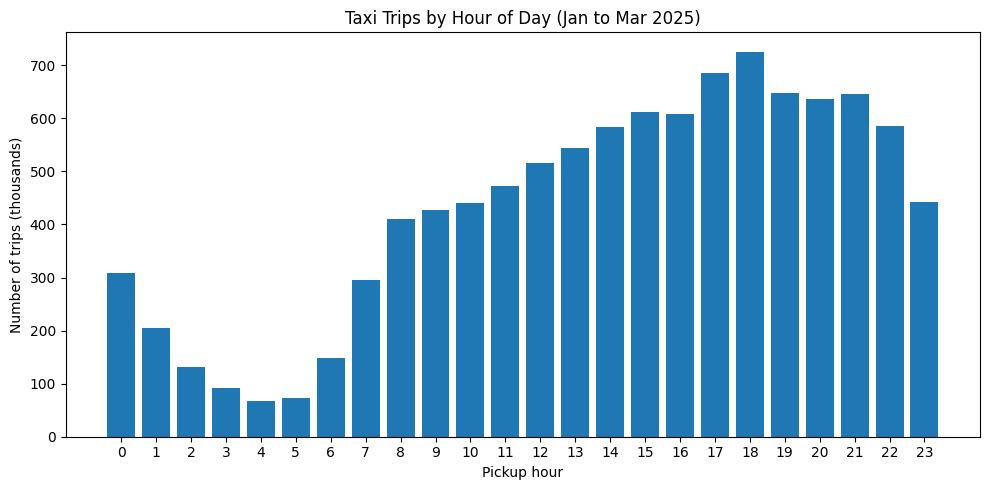

In [28]:
hour_pd = trips_by_hour.toPandas()

plt.figure(figsize=(10, 5))
plt.bar(hour_pd["pickup_hour"], hour_pd["trips"] / 1e3, color="#1f77b4")
plt.title("Taxi Trips by Hour of Day (Jan to Mar 2025)")
plt.xlabel("Pickup hour")
plt.ylabel("Number of trips (thousands)")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/nyc-taxi-driver-scheduling/trips_by_hour.png", dpi=150)
plt.show()

### Trips by Day of Week

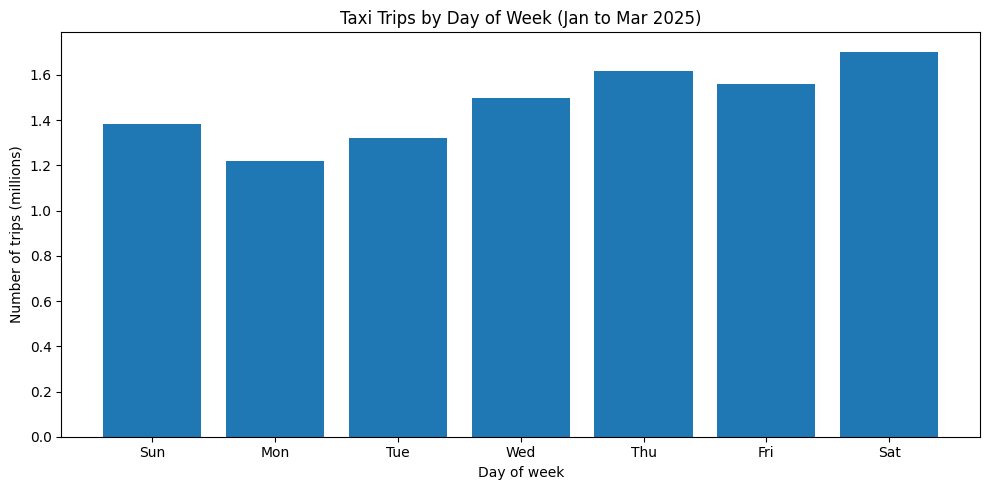

In [29]:
day_pd = trips_by_day.toPandas()

plt.figure(figsize=(10, 5))
plt.bar(day_pd["day_name"], day_pd["trips"] / 1e6, color="#1f77b4")
plt.title("Taxi Trips by Day of Week (Jan to Mar 2025)")
plt.xlabel("Day of week")
plt.ylabel("Number of trips (millions)")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/nyc-taxi-driver-scheduling/trips_by_day.png", dpi=150)
plt.show()

### Fare per Minute by Hour, Speed by Hour, Busiest Zones, and Airport vs City

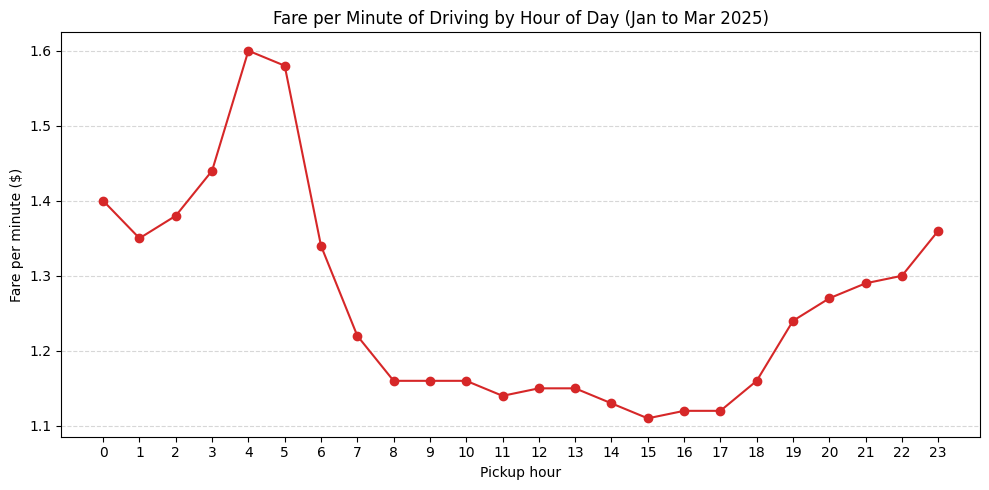

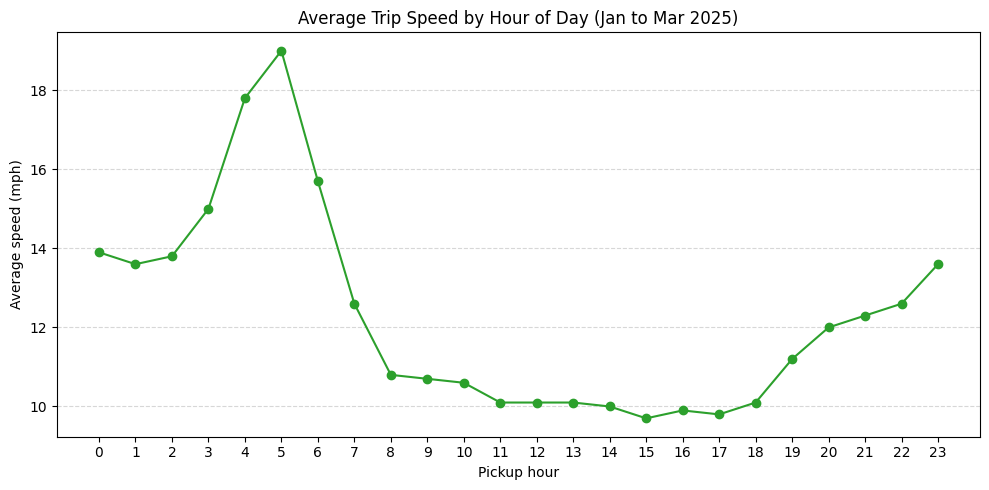

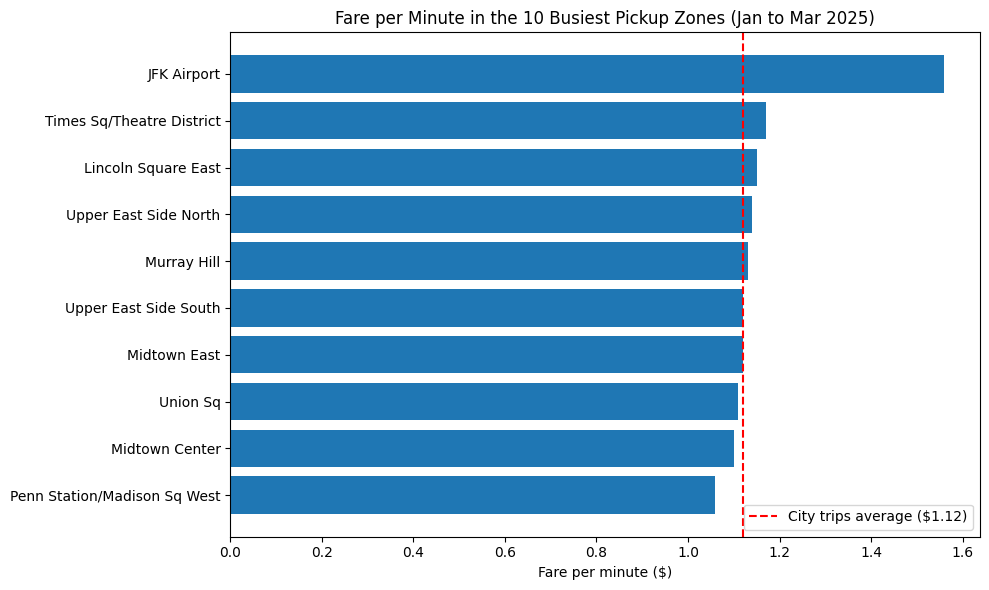

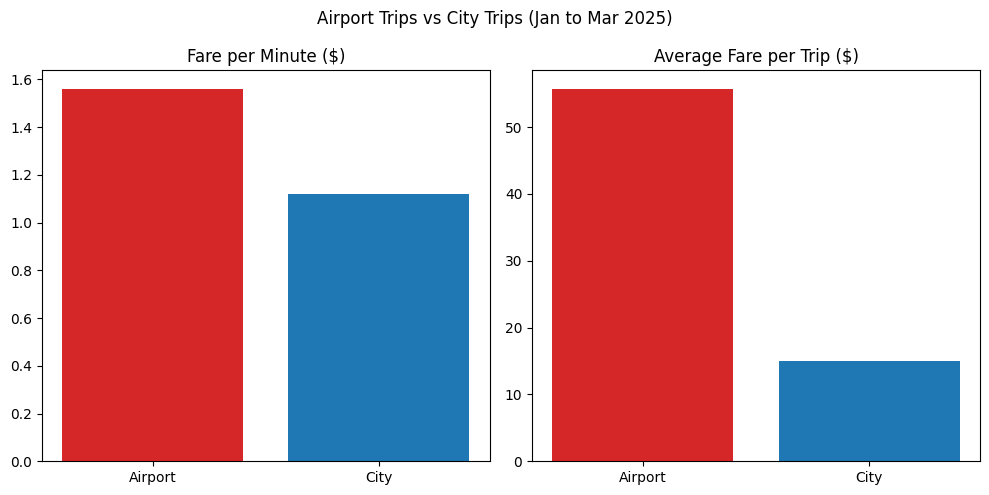

In [30]:
# 1. Fare per minute by hour
earn_pd = earn_by_hour.toPandas()
plt.figure(figsize=(10, 5))
plt.plot(earn_pd["pickup_hour"], earn_pd["fare_per_min"], marker="o", color="#d62728")
plt.title("Fare per Minute of Driving by Hour of Day (Jan to Mar 2025)")
plt.xlabel("Pickup hour")
plt.ylabel("Fare per minute ($)")
plt.xticks(range(0, 24))
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/nyc-taxi-driver-scheduling/fare_per_min_by_hour.png", dpi=150)
plt.show()

# 2. Average speed by hour
speed_pd = speed_by_hour.toPandas()
plt.figure(figsize=(10, 5))
plt.plot(speed_pd["pickup_hour"], speed_pd["avg_speed_mph"], marker="o", color="#2ca02c")
plt.title("Average Trip Speed by Hour of Day (Jan to Mar 2025)")
plt.xlabel("Pickup hour")
plt.ylabel("Average speed (mph)")
plt.xticks(range(0, 24))
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/nyc-taxi-driver-scheduling/speed_by_hour.png", dpi=150)
plt.show()

# 3. Fare per minute in the 10 busiest zones
busy_pd = busy_zones.limit(10).toPandas().sort_values("fare_per_min")
plt.figure(figsize=(10, 6))
plt.barh(busy_pd["Zone"], busy_pd["fare_per_min"], color="#1f77b4")
plt.axvline(1.12, color="red", linestyle="--", label="City trips average ($1.12)")
plt.title("Fare per Minute in the 10 Busiest Pickup Zones (Jan to Mar 2025)")
plt.xlabel("Fare per minute ($)")
plt.legend()
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/nyc-taxi-driver-scheduling/busy_zones_fare_per_min.png", dpi=150)
plt.show()

# 4. Airport vs city
ac_pd = airport_vs_city.toPandas()
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].bar(ac_pd["trip_type"], ac_pd["fare_per_min"], color=["#d62728", "#1f77b4"])
axes[0].set_title("Fare per Minute ($)")
axes[1].bar(ac_pd["trip_type"], ac_pd["avg_fare"], color=["#d62728", "#1f77b4"])
axes[1].set_title("Average Fare per Trip ($)")
fig.suptitle("Airport Trips vs City Trips (Jan to Mar 2025)")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/nyc-taxi-driver-scheduling/airport_vs_city.png", dpi=150)
plt.show()

### Trip Distance

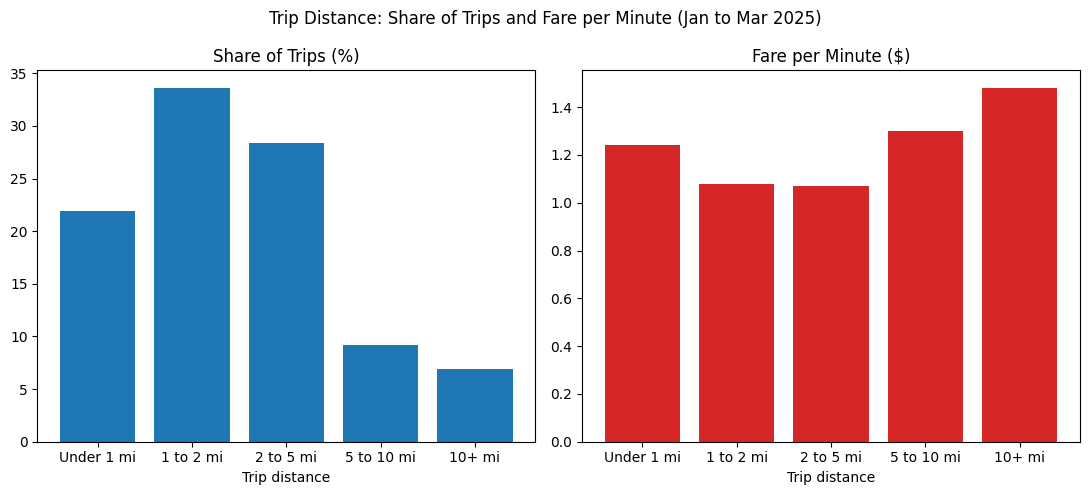

In [31]:
dist_pd = dist_summary.toPandas()

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].bar(dist_pd["distance_band"], dist_pd["pct_of_trips"], color="#1f77b4")
axes[0].set_title("Share of Trips (%)")
axes[0].set_xlabel("Trip distance")

axes[1].bar(dist_pd["distance_band"], dist_pd["fare_per_min"], color="#d62728")
axes[1].set_title("Fare per Minute ($)")
axes[1].set_xlabel("Trip distance")

fig.suptitle("Trip Distance: Share of Trips and Fare per Minute (Jan to Mar 2025)")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/nyc-taxi-driver-scheduling/trips_by_distance.png", dpi=150)
plt.show()